# FlashEats: Class 5 Investigation

## Client escalation

> **“Late deliveries are increasing and customers say our ETA is unreliable. Figure out what is happening before we invest in an AI delay-prediction system.”**

Today is not a syntax lesson. Your job is to use SQL, CSV, JSON and APIs like an FDE:

**define the question → retrieve evidence → validate completeness → reconcile sources → state what you know and what you still cannot know**

### Rules
- Do not train an ML model.
- State your definition of **late** before calculating it.
- Preserve raw API responses.
- Do not silently drop failures.
- If another team gets a different answer, investigate the definition and data grain first.

In [1]:
# 0. INSTALLS + IMPORTS
%pip install -q pandas requests flask matplotlib

import os, sys, json, time, sqlite3, subprocess, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

print("Environment ready.")

Note: you may need to restart the kernel to use updated packages.


Environment ready.


In [2]:
# 1. LOAD THE CLASSROOM PACK
# works locally (notebook sits in the pack root) and in Colab (upload the zip)

def find_pack(root):
    for db in Path(root).rglob("flasheats.db"):
        if db.parent.name == "database":
            return db.parent.parent
    return None

BASE = None
for cand in [Path.cwd(), Path.cwd().parent, Path("/content/FlashEats_Classroom_Pack")]:
    if (cand / "database" / "flasheats.db").exists():
        BASE = cand
        break

if BASE is None:
    try:
        from google.colab import files
        print("Upload FlashEats_Classroom_Pack.zip")
        uploaded = files.upload()
        zip_name = next(name for name in uploaded if name.endswith(".zip"))
        with zipfile.ZipFile(zip_name, "r") as z:
            z.extractall("/content")
        BASE = find_pack("/content")
    except Exception as e:
        print("If running locally, set BASE manually to the extracted pack.")
        print(e)

print("BASE:", BASE)
print("Exists:", BASE is not None and BASE.exists())

BASE: /home/utkuputku/Desktop/flasheats-classroom-pack
Exists: True


## 2. Source map first

Before analysis, predict where you would look for:

| Information | Likely source | Why? |
|---|---|---|
| Promised delivery time |  |  |
| Actual delivery time |  |  |
| Driver assignment |  |  |
| Customer complaint |  |  |
| Restaurant status |  |  |
| Driver movement/events |  |  |

**Discuss:** Which source is authoritative for each fact, and which is only contextual?

### My source map

| Information | Source | Authoritative or context? |
|---|---|---|
| Promised delivery time | `orders.promised_eta` (SQLite) | Authoritative. It's the promise the customer was given. Dispatch `current_delivery_eta` is a live ETA that keeps moving, so it's not the promise |
| Actual delivery time | `orders.actual_delivery_at`, backed up by `delivered` in `driver_events.json` | Authoritative, but the DB has holes, the driver app fills them |
| Driver assignment | Dispatch API (`driver_id`, `original_driver_id`, `reassigned_at`) | Authoritative. `orders.driver_id` only keeps the original driver |
| Customer complaint | `support_tickets.csv` | Context. Self reported, only covers people who complained |
| Restaurant status | `restaurant_status.csv` | Context. One manual snapshot per order, often stale |
| Driver movement/events | `driver_events.json` | Pickup/delivery are observed, location is only GPS pings, so anything about "where was the driver" is inferred |

Rule of thumb I'm using: the order platform owns the promise and the outcome, dispatch owns who was driving, everything else explains why.

In [3]:
# 3. BASIC SYNTAX: READ EVERY SOURCE

# SQLite
db_path = BASE / "database" / "flasheats.db"
con = sqlite3.connect(db_path)

tables = pd.read_sql(
    "SELECT name FROM sqlite_master WHERE type='table' ORDER BY name;",
    con
)
display(tables)

sample_orders = pd.read_sql("SELECT * FROM orders LIMIT 5;", con)
display(sample_orders)

# CSV
tickets = pd.read_csv(BASE / "data" / "support_tickets.csv")
restaurant_status = pd.read_csv(BASE / "data" / "restaurant_status.csv")
display(tickets.head())

# Nested JSON
with open(BASE / "data" / "driver_events.json", "r") as f:
    driver_events = json.load(f)

print("Driver objects:", len(driver_events))
display(driver_events[:1])

,name
0,customers
1,drivers
2,orders
3,restaurants


,order_id,customer_id,restaurant_id,driver_id,city,created_at,promised_eta,pickup_at,actual_delivery_at,final_status,distance_km_estimate,traffic_bucket,weather_bucket
0,O00001,C0168,R009,D103,Bengaluru,2026-08-13T12:56:00,2026-08-13T14:11:36,2026-08-13T13:35:49.825561,2026-08-13T14:22:25.035899,delivered,18.00,medium,clear
1,O00002,C0043,R018,D083,Bengaluru,2026-08-01T18:36:00,2026-08-01T19:43:16.627988,2026-08-01T18:58:24.735336,2026-08-01T19:47:14.818533,delivered,9.37,severe,clear
2,O00003,C0855,R010,D039,Bengaluru,2026-08-01T19:35:00,2026-08-01T20:17:52.941967,2026-08-01T19:57:50.820366,2026-08-01T20:13:28.061191,delivered,2.42,medium,clear
3,O00004,C0229,R030,D038,Bengaluru,2026-08-09T18:16:00,2026-08-09T19:30:19.067006,2026-08-09T18:46:48.725485,NaN,cancelled,14.20,high,rain
4,O00005,C0040,R004,D047,Bengaluru,2026-08-06T20:35:00,2026-08-06T21:54:48,2026-08-06T21:18:38.024280,2026-08-06T22:15:49.290713,delivered,18.00,high,clear


,ticket_id,order_id,created_at,category,customer_message
0,T00001,NaN,2026-08-26T23:34:00,late_delivery,My order is already past the promised time.
1,T00002,NaN,2026-08-24T13:49:00,eta_changed,The ETA keeps changing and the food is still not here.
2,T00003,NaN,2026-08-25T18:22:00,status_mismatch,The app says picking up but the restaurant says it is ready.
3,T00004,O00037,2026-08-09T21:09:00,Late Delivery,The rider has not moved for 15 minutes.
4,T00005,O00040,2026-08-11T20:15:00,late_delivery,My order is already past the promised time.


Driver objects: 120


[{'driver_id': 'D001',
  'events': [{'order_id': 'O00162',
    'type': 'assigned',
    'timestamp': '2026-08-26T17:53:25.977803'},
   {'order_id': 'O00162',
    'type': 'gps_ping',
    'timestamp': '2026-08-26T18:10:59.372420',
    'lat': 12.826339,
    'lon': 77.448282},
   {'order_id': 'O00162',
    'type': 'gps_ping',
    'timestamp': '2026-08-26T18:28:32.767037',
    'lat': 12.876013,
    'lon': 77.477707},
   {'order_id': 'O00162',
    'type': 'gps_ping',
    'timestamp': '2026-08-26T18:46:06.161653',
    'lat': 12.925686,
    'lon': 77.507133},
   {'order_id': 'O00162',
    'type': 'gps_ping',
    'timestamp': '2026-08-26T19:03:39.556270',
    'lat': 12.97536,
    'lon': 77.536558},
   {'order_id': 'O00162',
    'type': 'picked_up',
    'timestamp': '2026-08-26T18:27:32.131791'},
   {'order_id': 'O00162',
    'type': 'delivered',
    'timestamp': '2026-08-26T19:21:12.950887'},
   {'order_id': 'O00180',
    'type': 'assigned',
    'timestamp': '2026-08-08T18:05:08.439625'},
   {'o

# Challenge 1: How large is the late-delivery problem?

Before coding, decide:

- **Late means:** ______________________________
- **Denominator:** _____________________________
- **Cancelled orders:** include / exclude / other?
- **Missing actual delivery timestamp:** what will you do?
- **Row grain:** what does one row represent?

### Required analysis
1. valid delivered orders,
2. late count and percentage,
3. median lateness among late orders,
4. worst delayed orders,
5. any data-quality issue that changes the metric.

### My definitions (decided before calculating)

- Late means: delivered after `promised_eta`, any amount over 0 minutes. I also report the >10 min version since that's the "customer actually cares" number.
- Denominator: unique orders that were delivered, have a delivery timestamp, and have a sane promise (promise after order creation).
- Cancelled orders: excluded from the late rate, they never got delivered so on time/late doesn't apply. Reported separately so they don't vanish.
- Missing actual delivery timestamp: don't drop and don't guess. The driver app has a `delivered` event for these, so I backfill from there and flag the row. I show the number with and without backfill.
- Row grain: one row = one order after dropping duplicate `order_id`s. Raw table is not at that grain.

In [4]:
orders_raw = pd.read_sql("SELECT * FROM orders", con)
print("raw rows:", len(orders_raw), "| unique order_ids:", orders_raw["order_id"].nunique())

# the duplicates aren't clean copies, they disagree on traffic_bucket
dupes = orders_raw[orders_raw["order_id"].duplicated(keep=False)].sort_values("order_id")
display(dupes[["order_id", "created_at", "actual_delivery_at", "traffic_bucket"]])

orders = orders_raw.drop_duplicates("order_id", keep="first").copy()
ts_cols = ["created_at", "promised_eta", "pickup_at", "actual_delivery_at"]
for c in ts_cols:
    orders[c] = pd.to_datetime(orders[c], format="mixed", errors="coerce")

orders["status"] = orders["final_status"].str.strip().str.lower()
orders["traffic"] = orders["traffic_bucket"].str.strip().str.lower()

print("\nfinal_status as stored:")
print(orders["final_status"].value_counts())
print("\nnulls after dedupe:")
print(orders.isna().sum()[lambda s: s > 0])

raw rows: 1603 | unique order_ids: 1600


,order_id,created_at,actual_delivery_at,traffic_bucket
119,O00120,2026-08-13T18:15:00,2026-08-13T19:34:08.431508,severe
1600,O00120,2026-08-13T18:15:00,2026-08-13T19:34:08.431508,medium
722,O00723,2026-08-05T21:04:00,2026-08-05T22:04:30.928322,medium
1601,O00723,2026-08-05T21:04:00,2026-08-05T22:04:30.928322,high
1301,O01302,2026-08-26T21:07:00,2026-08-26T22:20:27.428561,medium
1602,O01302,2026-08-26T21:07:00,2026-08-26T22:20:27.428561,high



final_status as stored:
final_status
delivered    1527
cancelled      68
Delivered       5
Name: count, dtype: int64

nulls after dedupe:
restaurant_id           3
driver_id               3
actual_delivery_at    105
dtype: int64


In [5]:
# driver app events: second opinion on pickup + delivery times
flat = pd.DataFrame([{"driver_id": d["driver_id"], **e} for d in driver_events for e in d["events"]])
flat["timestamp"] = pd.to_datetime(flat["timestamp"], format="mixed")

app = (flat[flat["type"].isin(["picked_up", "delivered"])]
       .pivot_table(index="order_id", columns="type", values="timestamp", aggfunc="first")
       .rename(columns={"picked_up": "app_pickup_at", "delivered": "app_delivered_at"}))
orders = orders.merge(app, left_on="order_id", right_index=True, how="left")

both = orders.dropna(subset=["actual_delivery_at", "app_delivered_at"])
agree = ((both["actual_delivery_at"] - both["app_delivered_at"]).abs() < pd.Timedelta("1s")).mean()
print(f"delivery time, DB vs driver app, where both exist: {agree:.1%} match")

no_db_time = orders["status"].eq("delivered") & orders["actual_delivery_at"].isna()
print("delivered orders with no DB delivery time:", no_db_time.sum(),
      "| of those, driver app has it:", orders.loc[no_db_time, "app_delivered_at"].notna().sum())

orders["delivered_at"] = orders["actual_delivery_at"].fillna(orders["app_delivered_at"])
orders["delivery_ts_source"] = np.where(orders["actual_delivery_at"].notna(), "db",
                                np.where(orders["app_delivered_at"].notna(), "driver_app_backfill", "missing"))

# timestamp sanity
orders["bad_eta"] = orders["promised_eta"] <= orders["created_at"]
orders["bad_pickup"] = orders["pickup_at"] > orders["delivered_at"]
print("\npromise before the order was even created:", orders["bad_eta"].sum())
display(orders.loc[orders["bad_eta"], ["order_id", "created_at", "promised_eta", "delivered_at"]])
print("DB pickup after delivery:", orders["bad_pickup"].sum())
display(orders.loc[orders["bad_pickup"], ["order_id", "pickup_at", "app_pickup_at", "delivered_at"]])

# cancelled orders still have a DB pickup_at, but the driver app never picked them up
canc = orders["status"].eq("cancelled")
print("cancelled orders with a DB pickup_at:", orders.loc[canc, "pickup_at"].notna().sum(),
      "| with a driver app pickup:", orders.loc[canc, "app_pickup_at"].notna().sum())

# use driver app pickup where the DB one is broken, and never trust pickup on cancelled orders
orders["pickup_fixed"] = orders["pickup_at"].where(~orders["bad_pickup"], orders["app_pickup_at"])
orders.loc[canc, "pickup_fixed"] = pd.NaT

delivery time, DB vs driver app, where both exist: 100.0% match
delivered orders with no DB delivery time: 37 | of those, driver app has it: 37

promise before the order was even created: 4


,order_id,created_at,promised_eta,delivered_at
100,O00101,2026-08-24 20:59:00,2026-08-24 20:49:00,2026-08-24 22:14:30.685278
101,O00102,2026-08-11 16:41:00,2026-08-11 16:31:00,2026-08-11 17:57:17.661772
102,O00103,2026-08-22 20:11:00,2026-08-22 20:01:00,2026-08-22 21:10:17.342305
103,O00104,2026-08-09 22:19:00,2026-08-09 22:09:00,2026-08-09 23:36:20.740161


DB pickup after delivery: 5


,order_id,pickup_at,app_pickup_at,delivered_at
50,O00051,2026-08-01 16:24:51.495665,2026-08-01 15:25:54.609569,2026-08-01 16:19:51.495665
51,O00052,2026-08-24 18:16:16.946011,2026-08-24 17:19:34.353083,2026-08-24 18:11:16.946011
52,O00053,2026-08-13 18:25:53.797613,2026-08-13 17:42:23.641275,2026-08-13 18:20:53.797613
53,O00054,2026-08-28 21:25:10.582862,2026-08-28 20:23:52.944934,2026-08-28 21:20:10.582862
54,O00055,2026-08-16 14:08:05.645770,2026-08-16 13:20:04.394373,2026-08-16 14:03:05.645770


cancelled orders with a DB pickup_at: 68 | with a driver app pickup: 0


In [6]:
# population waterfall so anyone can see where rows go
steps = [
    ("raw rows in orders table", len(orders_raw)),
    ("unique orders", len(orders)),
    ("minus cancelled", int((orders["status"] == "delivered").sum())),
    ("  of which have a DB delivery time", int((orders["status"].eq("delivered") & orders["actual_delivery_at"].notna()).sum())),
    ("  after driver app backfill", int((orders["status"].eq("delivered") & orders["delivered_at"].notna()).sum())),
]
valid = orders["status"].eq("delivered") & orders["delivered_at"].notna() & ~orders["bad_eta"]
steps.append(("minus broken promise times = final denominator", int(valid.sum())))
display(pd.DataFrame(steps, columns=["step", "orders"]))

orders["delay_min"] = (orders["delivered_at"] - orders["promised_eta"]).dt.total_seconds() / 60
d = orders[valid].copy()
d["late"] = d["delay_min"] > 0

late_n = int(d["late"].sum())
print(f"\nlate (>0 min): {late_n} of {len(d)} = {d['late'].mean():.1%}")
print(f"late (>10 min): {(d['delay_min'] > 10).sum()} of {len(d)} = {(d['delay_min'] > 10).mean():.1%}")
late_only = d.loc[d["late"], "delay_min"]
print(f"median lateness among late orders: {late_only.median():.1f} min | p90: {late_only.quantile(.9):.1f} min")
print(f"median delay across all delivered orders: {d['delay_min'].median():.1f} min")

,step,orders
0,raw rows in orders table,1603
1,unique orders,1600
2,minus cancelled,1532
3,of which have a DB delivery time,1495
4,after driver app backfill,1532
5,minus broken promise times = final denominator,1528



late (>0 min): 863 of 1528 = 56.5%
late (>10 min): 354 of 1528 = 23.2%
median lateness among late orders: 8.0 min | p90: 22.1 min
median delay across all delivered orders: 1.4 min


In [7]:
print("worst delayed valid orders:")
display(d.sort_values("delay_min", ascending=False)
        [["order_id", "restaurant_id", "created_at", "promised_eta", "delivered_at", "delay_min", "traffic", "weather_bucket", "delivery_ts_source"]]
        .head(10).assign(delay_min=lambda x: x["delay_min"].round(1)))

print("what the worst list looks like if you don't catch the broken ETAs:")
display(orders[orders["status"].eq("delivered")].sort_values("delay_min", ascending=False)
        [["order_id", "created_at", "promised_eta", "delay_min", "bad_eta"]].head(6))

worst delayed valid orders:


,order_id,restaurant_id,created_at,promised_eta,delivered_at,delay_min,traffic,weather_bucket,delivery_ts_source
1080,O01081,R048,2026-08-13 17:14:00,2026-08-13 18:15:46.613098,2026-08-13 19:06:02.677891,50.3,high,clear,db
472,O00473,R002,2026-08-14 18:58:00,2026-08-14 20:17:48.000000,2026-08-14 21:04:00.769224,46.2,high,clear,db
1101,O01102,R021,2026-08-12 18:25:00,2026-08-12 19:31:12.651822,2026-08-12 20:16:09.835907,45.0,medium,clear,db
193,O00194,R020,2026-08-11 17:36:00,2026-08-11 19:01:48.000000,2026-08-11 19:40:08.111510,38.3,high,heavy_rain,db
1311,O01312,R027,2026-08-14 19:02:00,2026-08-14 20:17:36.000000,2026-08-14 20:54:36.321890,37.0,medium,clear,db
1402,O01403,R014,2026-08-24 17:26:00,2026-08-24 18:47:36.000000,2026-08-24 19:24:32.047659,36.9,medium,heavy_rain,db
459,O00460,R026,2026-08-12 16:27:00,2026-08-12 17:52:24.000000,2026-08-12 18:29:16.970368,36.9,severe,clear,db
736,O00737,R027,2026-08-20 20:10:00,2026-08-20 21:11:15.896462,2026-08-20 21:47:32.398594,36.3,low,clear,db
63,O00064,R002,2026-08-09 19:22:00,2026-08-09 20:29:56.928762,2026-08-09 21:05:34.486949,35.6,medium,clear,db
205,O00206,R017,2026-08-24 15:22:00,2026-08-24 16:24:00.543725,2026-08-24 16:59:27.120052,35.4,high,clear,driver_app_backfill


what the worst list looks like if you don't catch the broken ETAs:


,order_id,created_at,promised_eta,delay_min,bad_eta
103,O00104,2026-08-09 22:19:00,2026-08-09 22:09:00.000000,87.345669,True
101,O00102,2026-08-11 16:41:00,2026-08-11 16:31:00.000000,86.294363,True
100,O00101,2026-08-24 20:59:00,2026-08-24 20:49:00.000000,85.511421,True
102,O00103,2026-08-22 20:11:00,2026-08-22 20:01:00.000000,69.289038,True
1080,O01081,2026-08-13 17:14:00,2026-08-13 18:15:46.613098,50.267747,False
472,O00473,2026-08-14 18:58:00,2026-08-14 20:17:48.000000,46.212820,False


In [8]:
# how much each choice moves the number
def rate(mask, thresh=0):
    x = orders.loc[mask, "delay_min"]
    return pd.Series({"orders": len(x), "late_rate": (x > thresh).mean()})

deliv = orders["status"].eq("delivered")
raw = orders_raw.copy()
for c in ["promised_eta", "actual_delivery_at"]:
    raw[c] = pd.to_datetime(raw[c], format="mixed")
raw_delay = (raw["actual_delivery_at"] - raw["promised_eta"]).dt.total_seconds() / 60

sens = pd.DataFrame({
    "raw rows, all rows as denominator": pd.Series({"orders": len(raw), "late_rate": (raw_delay > 0).sum() / len(raw)}),
    "DB only, delivered with timestamp (old dashboard)": rate(deliv & orders["actual_delivery_at"].notna()),
    "+ driver app backfill": rate(deliv & orders["delivered_at"].notna()),
    "+ drop broken ETAs (my headline)": rate(valid),
    "same but >10 min": rate(valid, 10),
}).T
sens["late_rate"] = (sens["late_rate"] * 100).round(1)
display(sens)

,orders,late_rate
"raw rows, all rows as denominator",1603.0,52.7
"DB only, delivered with timestamp (old dashboard)",1495.0,56.4
+ driver app backfill,1532.0,56.6
+ drop broken ETAs (my headline),1528.0,56.5
same but >10 min,1528.0,23.2


### Challenge 1 answer

56.5% of delivered orders arrive after the promised time (863 of 1,528). Only 23% are more than 10 minutes late. So yes, lots of orders are late, but most of them by a few minutes. Median lateness among late orders is 8 min, p90 is 22 min.

Data issues I found, and whether they move the number:
- 3 duplicated `order_id`s (1,603 rows vs 1,600 orders). The copies disagree on `traffic_bucket`, so it's not a harmless duplicate. Tiny effect on the rate, but it'd mess with any traffic breakdown if you didn't dedupe.
- 37 orders marked delivered with no `actual_delivery_at` in the DB. The driver app has all 37, and where both sources have a time they match 100%, so backfilling is safe. 24 of the 37 were late, so they skew late, which is why the rate ticks up once they're back in.
- 4 orders (O00101 to O00104) have a promised ETA 10 min before the order was even created. They show up as the "worst" delays (70 to 87 min) but that's a broken promise field, not a bad delivery. Excluded and flagged.
- 5 orders (O00051 to O00055) have a DB pickup time 5 min after delivery. Driver app pickup looks right, so I use that for anything pickup related. Doesn't affect delay.
- All 68 cancelled orders have a `pickup_at` in the DB, but the driver app never picked any of them up. So DB pickup on cancelled orders is junk.
- `final_status` has `Delivered` vs `delivered`, that's just casing.

If another team says 52.7% they probably divided by raw rows including cancelled ones. If they say 56.4% they used the old dashboard definition (DB only). Same data, different denominator, that's the conversation to have.

## Checkpoint

Compare your answer with another team.

If your counts differ, investigate:
- duplicate rows,
- cancelled orders,
- missing timestamps,
- late-delivery definition,
- row grain.

# Challenge 2: Operations says: “Traffic is the problem.”

Test that claim using at least three dimensions.

Possible dimensions:
- traffic,
- weather,
- distance,
- time of day,
- restaurant,
- driver.

### Required output
- 2-3 comparisons,
- one chart or compact table,
- one hypothesis supported by evidence,
- one alternative explanation you cannot rule out.

Separate **association** from **causation**.

In [9]:
# delay = time before pickup vs time on the road
d["prep_min"] = (d["pickup_fixed"] - d["created_at"]).dt.total_seconds() / 60   # order placed -> driver picks up
d["ride_min"] = (d["delivered_at"] - d["pickup_fixed"]).dt.total_seconds() / 60  # pickup -> door
d["promise_min"] = (d["promised_eta"] - d["created_at"]).dt.total_seconds() / 60
d["hour"] = d["created_at"].dt.hour

def summarize(col):
    return (d.groupby(col, observed=True)
             .agg(orders=("order_id", "count"),
                  late_rate=("late", "mean"),
                  median_delay=("delay_min", "median"),
                  median_prep=("prep_min", "median"),
                  median_ride=("ride_min", "median"),
                  median_promise=("promise_min", "median"))
             .round(2))

traffic_order = ["low", "medium", "high", "severe"]
d["traffic"] = pd.Categorical(d["traffic"], traffic_order, ordered=True)
print("by traffic"); display(summarize("traffic"))
print("by weather"); display(summarize("weather_bucket"))

by traffic


,orders,late_rate,median_delay,median_prep,median_ride,median_promise
traffic,,,,,,
low,368,0.50,0.02,25.91,43.47,72.8
medium,599,0.52,0.33,25.92,46.79,75.6
high,434,0.66,3.77,26.90,53.05,79.8
severe,127,0.65,4.26,24.90,61.54,85.4


by weather


,orders,late_rate,median_delay,median_prep,median_ride,median_promise
weather_bucket,,,,,,
clear,1218,0.53,0.80,26.17,46.07,72.80
heavy_rain,72,0.74,6.63,24.78,60.02,81.45
rain,238,0.67,4.19,26.52,51.83,75.30


In [10]:
print("correlation with delay_min:")
print(d[["prep_min", "ride_min", "promise_min", "distance_km_estimate"]].corrwith(d["delay_min"]).round(2))

d["prep_bucket"] = pd.cut(d["prep_min"], [0, 18, 24, 30, 36, 200], labels=["<18", "18-24", "24-30", "30-36", "36+"])
print("\nby time from order to pickup")
display(summarize("prep_bucket"))

# distance looks like it has a default value baked in
print("orders with distance exactly 18.00 km:", (orders["distance_km_estimate"] == 18).sum(), "of", len(orders))

correlation with delay_min:


prep_min                0.94
ride_min                0.22
promise_min             0.12
distance_km_estimate    0.06
dtype: float64

by time from order to pickup


,orders,late_rate,median_delay,median_prep,median_ride,median_promise
prep_bucket,,,,,,
<18,249,0.01,-9.95,15.17,46.84,73.03
18-24,361,0.20,-3.65,21.01,47.82,72.80
24-30,390,0.68,1.57,26.57,45.47,72.80
30-36,230,0.97,7.90,32.45,48.14,72.80
36+,298,1.00,18.11,42.10,48.53,74.44


orders with distance exactly 18.00 km: 806 of 1600


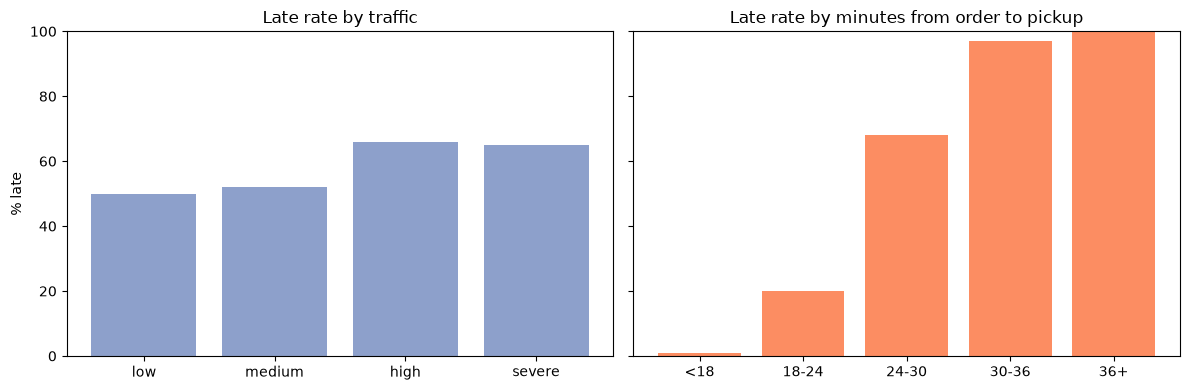

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
t = summarize("traffic")
axes[0].bar(t.index.astype(str), t["late_rate"] * 100, color="#8da0cb")
axes[0].set_title("Late rate by traffic")
axes[0].set_ylabel("% late")
p = summarize("prep_bucket")
axes[1].bar(p.index.astype(str), p["late_rate"] * 100, color="#fc8d62")
axes[1].set_title("Late rate by minutes from order to pickup")
for ax in axes:
    ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

In [12]:
# restaurants and drivers
rest = (d.groupby("restaurant_id")
          .agg(orders=("order_id", "count"), late_orders=("late", "sum"), late_rate=("late", "mean"), median_prep=("prep_min", "median"))
          .sort_values("late_orders", ascending=False))
print("restaurants with the most late orders:")
display(rest.head(8).round(2))
print(f"restaurant late rates range {rest['late_rate'].min():.0%} to {rest['late_rate'].max():.0%}, "
      f"but each has only {rest['orders'].min()} to {rest['orders'].max()} orders")
print("late orders from top 10 restaurants:", f"{rest['late_orders'].head(10).sum() / rest['late_orders'].sum():.0%} of all late orders (10 of 60 restaurants)")

drivers = pd.read_sql("SELECT * FROM drivers", con)
dd = d.merge(drivers, on="driver_id", how="left")
print("\ndriver attributes vs delay (correlation):")
print(dd[["rating", "experience_months"]].corrwith(dd["delay_min"]).round(3))
display(dd.groupby("vehicle_type").agg(orders=("order_id", "count"), late_rate=("late", "mean")).round(3))

restaurants with the most late orders:


,orders,late_orders,late_rate,median_prep
restaurant_id,,,,
R050,35,22,0.63,28.19
R024,26,21,0.81,29.56
R023,32,20,0.62,28.05
R004,30,20,0.67,30.50
R030,38,20,0.53,23.43
R051,29,20,0.69,26.62
R018,28,19,0.68,30.19
R045,29,19,0.66,30.82


restaurant late rates range 35% to 81%, but each has only 15 to 38 orders
late orders from top 10 restaurants: 23% of all late orders (10 of 60 restaurants)

driver attributes vs delay (correlation):
rating               0.018
experience_months   -0.004
dtype: float64


,orders,late_rate
vehicle_type,,
bike,867,0.569
ebike,167,0.599
scooter,491,0.548


### Challenge 2 answer

Traffic is part of the story, but it's not the main thing.

- Late rate is higher in high/severe traffic (~66%) than low/medium (~50%). Same pattern with rain and heavy rain. So there is an association.
- But look at where the time goes. Time on the road does grow with traffic (median ride ~43 min low vs ~62 min severe), and the promise grows with it (~73 vs ~85 min). The ETA already prices traffic in, mostly.
- Time from order to pickup is roughly the same in every traffic bucket (~26 min), and it's what actually tracks lateness. Correlation with delay is ~0.94 for time-to-pickup vs ~0.22 for ride time. Orders picked up within 18 min are late 1% of the time, orders picked up after 30 min are late 97 to 100% of the time.
- Distance can't be tested properly: ~806 of 1,600 orders have exactly 18.00 km, which looks like a default filled in when the real distance was missing.
- Driver rating, experience and vehicle type show basically nothing.
- Restaurants: late rate goes from ~35% to ~81% by restaurant, but with 15 to 38 orders each a lot of that is noise. No single restaurant is the problem, the top 10 (out of 60) cover only ~23% of late orders.

Hypothesis supported by the data: delay mostly builds up before the food leaves the restaurant, not on the road. Traffic and rain eat into the buffer, so they tip borderline orders over.

Alternative I can't rule out: the "prep" window mixes restaurant cooking time with the driver getting to the restaurant. There's no "driver arrived at restaurant" or "food ready" event, so I can't say whether it's slow kitchens or late drivers (Challenge 5 digs into this). All of this is association, not causation. Busy restaurants at dinner rush could also be in heavy traffic areas, for example.

# Challenge 3: Customer Support disagrees

Use `support_tickets.csv`.

### Questions
1. What are customers actually complaining about?
2. Which complaint types are most common?
3. Are ticket IDs unique?
4. Does the customer story match the operational story?
5. What can tickets tell you that timestamps cannot?

### Required output
A short **system view vs customer view** comparison.

In [13]:
display(tickets.head())

print("rows:", len(tickets), "| unique ticket_ids:", tickets["ticket_id"].nunique())
dup = tickets[tickets["ticket_id"].duplicated(keep=False)]
display(dup)
print("exact duplicate rows:", tickets.duplicated().sum(), "-> safe to drop")
t = tickets.drop_duplicates().copy()

print("tickets with no order_id:", t["order_id"].isna().sum())
print("ticket order_ids found in orders:", f"{t['order_id'].dropna().isin(orders['order_id']).mean():.0%}")

print("\ncategories as stored:")
print(t["category"].map(repr).value_counts())

,ticket_id,order_id,created_at,category,customer_message
0,T00001,NaN,2026-08-26T23:34:00,late_delivery,My order is already past the promised time.
1,T00002,NaN,2026-08-24T13:49:00,eta_changed,The ETA keeps changing and the food is still not here.
2,T00003,NaN,2026-08-25T18:22:00,status_mismatch,The app says picking up but the restaurant says it is ready.
3,T00004,O00037,2026-08-09T21:09:00,Late Delivery,The rider has not moved for 15 minutes.
4,T00005,O00040,2026-08-11T20:15:00,late_delivery,My order is already past the promised time.


rows: 202 | unique ticket_ids: 201


,ticket_id,order_id,created_at,category,customer_message
12,T00013,O00090,2026-08-20T18:14:00,late_delivery,My order is already past the promised time.
201,T00013,O00090,2026-08-20T18:14:00,late_delivery,My order is already past the promised time.


exact duplicate rows: 1 -> safe to drop
tickets with no order_id: 3
ticket order_ids found in orders: 100%

categories as stored:
category
'late_delivery'        37
'eta_changed'          37
'restaurant_delay'     37
'ready_but_waiting'    33
'status_mismatch'      29
'driver_not_moving'    25
'Late Delivery'         1
'late_delivery '        1
'ETA issue'             1
Name: count, dtype: int64


In [14]:
# representation fixes only (case, spaces). "ETA issue" is a meaning question so it's left alone
t["category_norm"] = t["category"].str.strip().str.lower().str.replace(" ", "_")
print(t["category_norm"].value_counts())

# does the category match the message? the message text is a fixed template per category
msg_to_cat = t.groupby("customer_message")["category_norm"].agg(lambda s: s.value_counts().index[0])
t["cat_from_msg"] = t["customer_message"].map(msg_to_cat)
print("\ncategory disagrees with message:")
display(t.loc[t["category_norm"] != t["cat_from_msg"], ["ticket_id", "order_id", "category", "customer_message"]])

theme = {"late_delivery": "lateness / ETA", "eta_changed": "lateness / ETA",
         "restaurant_delay": "restaurant / handoff", "ready_but_waiting": "restaurant / handoff",
         "status_mismatch": "restaurant / handoff", "driver_not_moving": "driver on the road"}
t["theme"] = t["cat_from_msg"].map(theme)
print("tickets by theme:")
print(t["theme"].value_counts())

category_norm
late_delivery        39
eta_changed          37
restaurant_delay     37
ready_but_waiting    33
status_mismatch      29
driver_not_moving    25
eta_issue             1
Name: count, dtype: int64

category disagrees with message:


,ticket_id,order_id,category,customer_message
3,T00004,O00037,Late Delivery,The rider has not moved for 15 minutes.
5,T00006,O00041,ETA issue,The rider has not moved for 15 minutes.


tickets by theme:
theme
restaurant / handoff    99
lateness / ETA          75
driver on the road      27
Name: count, dtype: int64


In [15]:
tk = t.merge(orders[["order_id", "status", "created_at", "promised_eta", "delivered_at", "delay_min"]],
             on="order_id", how="left", suffixes=("_ticket", ""))
tk["late"] = tk["delay_min"] > 0

print("orders with a ticket:", tk["order_id"].nunique(), "of", len(orders), f"({tk['order_id'].nunique() / len(orders):.0%})")
print(f"late rate for ticketed orders: {tk['late'].mean():.0%} vs {d['late'].mean():.0%} overall")
display(tk.groupby("cat_from_msg").agg(tickets=("ticket_id", "count"), late_rate=("late", "mean"), median_delay=("delay_min", "median")).round(2))

# when were tickets opened relative to the order?
tk["ticket_at"] = pd.to_datetime(tk["created_at_ticket"])
tk["min_after_order"] = (tk["ticket_at"] - tk["created_at"]).dt.total_seconds() / 60
tk["min_vs_promise"] = (tk["ticket_at"] - tk["promised_eta"]).dt.total_seconds() / 60
print(tk[["min_after_order", "min_vs_promise"]].describe().round(1))
late_msg = tk[tk["cat_from_msg"] == "late_delivery"]
print(f"'already past the promised time' tickets opened BEFORE the promise: {(late_msg['min_vs_promise'] < 0).mean():.0%}")

orders with a ticket: 198 of 1600 (12%)
late rate for ticketed orders: 82% vs 56% overall


,tickets,late_rate,median_delay
cat_from_msg,,,
driver_not_moving,27,0.70,10.37
eta_changed,37,0.78,7.65
late_delivery,38,0.84,14.11
ready_but_waiting,33,0.91,12.16
restaurant_delay,37,0.76,10.45
status_mismatch,29,0.90,12.68


       min_after_order  min_vs_promise
count            198.0           198.0
mean              37.2           -33.6
std               10.9            15.3
min               18.0           -64.3
25%               28.0           -45.0
50%               37.0           -35.2
75%               46.0           -23.7
max               55.0             5.5
'already past the promised time' tickets opened BEFORE the promise: 97%


### Challenge 3 answer

What customers complain about, after fixing just casing/spaces:
- ~50% restaurant / handoff stuff: "still preparing", "food is ready but no rider picked it up", "app says picking up but restaurant says ready"
- ~37% lateness / ETA changing
- ~13% "rider hasn't moved"

Ticket IDs are not unique: T00013 appears twice, but it's an exact duplicate row so it's safe to drop. 3 tickets have no `order_id` so they can't be tied to anything. Two tickets (T00004 "Late Delivery", T00006 "ETA issue") have a category that doesn't match the message, both messages say the rider hasn't moved. I didn't remap "ETA issue" on instinct, I'd ask support who owns the categories.

System view vs customer view:
- System view: ~56% late, mostly by a few minutes, and the late time builds up before pickup.
- Customer view: half the complaints are about the restaurant/handoff. That actually lines up with the system story, customers are basically describing the pickup delay from the outside.
- Where they disagree: ~18% of ticketed orders were delivered on time, so "customer complained" doesn't equal "late". And tickets only cover ~12% of orders, so they're a sample of the loudest customers, not the whole picture.

What tickets tell you that timestamps can't: why the customer felt it was late. "Food ready but no rider" vs "still preparing" is exactly the restaurant vs driver split we can't see in the timestamps.

One thing that doesn't add up: tickets are opened ~37 min after the order and ~34 min before the promised time on median, even the ones that say "already past the promised time". Either the ticket timestamp isn't when the customer wrote in, or customers are reacting to a different ETA than `promised_eta` (like the live one in the app). Either way I wouldn't use ticket timestamps to sequence events until someone explains that field.

# Challenge 4: Dispatch API: prove you retrieved everything

Your task:
1. start the API,
2. inspect one response,
3. retrieve **all** records,
4. handle pagination,
5. handle retryable failures,
6. save every successful raw page,
7. prove ingestion completeness.

A successful HTTP `200` on one page does **not** prove the job succeeded.

In [16]:
# Start the mock API
api_script = BASE / "api" / "mock_dispatch_api.py"

api_proc = subprocess.Popen(
    [sys.executable, str(api_script)],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

time.sleep(2)
health = requests.get("http://127.0.0.1:8000/health", timeout=10)
print(health.status_code, health.json())

200 {'service': 'flasheats-dispatch-api', 'status': 'ok'}


In [17]:
# Basic API syntax
API_URL = "http://127.0.0.1:8000/dispatch/orders"

response = requests.get(
    API_URL,
    params={"page": 1, "page_size": 50},
    timeout=10
)

print("HTTP:", response.status_code)

if response.ok:
    payload = response.json()
    print("Keys:", payload.keys())
    print("Records on page:", len(payload["data"]))
    print("Has more:", payload["has_more"])
    print("Reported total:", payload["total_records"])

HTTP: 200
Keys: dict_keys(['data', 'has_more', 'page', 'page_size', 'total_records'])
Records on page: 50
Has more: True
Reported total: 1600


In [18]:
RAW_DIR = BASE / "student_output" / "raw_dispatch"
RAW_DIR.mkdir(parents=True, exist_ok=True)
RETRYABLE = {429, 500, 502, 503, 504}

def fetch_page(page, page_size, max_attempts=5, log=None):
    for attempt in range(1, max_attempts + 1):
        try:
            r = requests.get(API_URL, params={"page": page, "page_size": page_size}, timeout=10)
        except requests.RequestException as e:
            status, body, wait = "network_error", str(e), 2 ** attempt * 0.25
        else:
            status = r.status_code
            if r.ok:
                log.append({"page": page, "attempt": attempt, "status": status})
                return r.json()
            body = r.text
            if status not in RETRYABLE:
                log.append({"page": page, "attempt": attempt, "status": status})
                raise RuntimeError(f"page {page}: non-retryable HTTP {status}: {body}")
            try:
                wait = float(r.json().get("retry_after_seconds", 2 ** attempt * 0.25))
            except ValueError:
                wait = 2 ** attempt * 0.25
        log.append({"page": page, "attempt": attempt, "status": status})
        print(f"page {page} attempt {attempt}: {status}, retrying in {wait}s")
        time.sleep(wait)
    raise RuntimeError(f"page {page}: gave up after {max_attempts} attempts")

def fetch_all_dispatch_orders(page_size=50):
    records, log, page, reported_total = [], [], 1, None
    while True:
        payload = fetch_page(page, page_size, log=log)
        (RAW_DIR / f"page_{page:03d}.json").write_text(json.dumps(payload, indent=2))  # raw, untouched
        records.extend(payload["data"])
        reported_total = payload["total_records"]
        if not payload["has_more"]:
            break
        page += 1

    ids = [r["order_id"] for r in records]
    checks = {
        "pages": page,
        "records_retrieved": len(records),
        "total_records_reported": reported_total,
        "count_matches": len(records) == reported_total,
        "unique_order_ids": len(set(ids)),
        "no_duplicates": len(set(ids)) == len(ids),
        "raw_pages_saved": len(list(RAW_DIR.glob("page_*.json"))),
    }
    (RAW_DIR / "ingestion_manifest.json").write_text(json.dumps({"checks": checks, "request_log": log}, indent=2))
    if not (checks["count_matches"] and checks["no_duplicates"]):
        raise RuntimeError(f"ingestion incomplete: {checks}")
    return records, checks, pd.DataFrame(log)

# restart the API so the injected failures on page 3 and 5 happen on this run
api_proc.terminate(); api_proc.wait()
api_proc = subprocess.Popen([sys.executable, str(api_script)], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
for _ in range(20):
    try:
        if requests.get("http://127.0.0.1:8000/health", timeout=1).ok:
            break
    except requests.RequestException:
        time.sleep(0.5)

dispatch_records, checks, request_log = fetch_all_dispatch_orders()
print(json.dumps(checks, indent=2))
print("\nnon-200 responses we survived:")
display(request_log[request_log["status"] != 200])

page 3 attempt 1: 500, retrying in 0.5s


page 5 attempt 1: 429, retrying in 1.0s


{
  "pages": 32,
  "records_retrieved": 1600,
  "total_records_reported": 1600,
  "count_matches": true,
  "unique_order_ids": 1600,
  "no_duplicates": true,
  "raw_pages_saved": 32
}

non-200 responses we survived:


,page,attempt,status
2,3,1,500
5,5,1,429


In [19]:
# prove it lines up with the order platform, not just with itself
dispatch = pd.DataFrame(dispatch_records)
for c in ["assigned_at", "reassigned_at", "estimated_pickup_at", "current_delivery_eta"]:
    dispatch[c] = pd.to_datetime(dispatch[c], format="mixed")

print("dispatch ids == order ids:", set(dispatch["order_id"]) == set(orders["order_id"]))

# single-record endpoint agrees with the paged data, and 404s cleanly
one = requests.get(f"{API_URL}/O00001", timeout=10).json()
print("detail endpoint matches paged record:", one == dispatch_records[0])
print("unknown order:", requests.get(f"{API_URL}/O99999", timeout=10).status_code)

x = orders.merge(dispatch, on="order_id", suffixes=("", "_dispatch"))
print("\nstatus crosstab:")
display(pd.crosstab(x["dispatch_status"], x["status"]))
print("orders.driver_id differs from dispatch driver:", (x["driver_id"] != x["driver_id_dispatch"]).sum(),
      "| dispatch says reassigned:", x["reassigned_at"].notna().sum(),
      "| orders.driver_id == original_driver_id:", (x["driver_id"].fillna("") == x["original_driver_id"]).sum())
print("orders missing driver_id that dispatch fills in:", x["driver_id"].isna().sum())

dispatch ids == order ids: True
detail endpoint matches paged record: True
unknown order: 404

status crosstab:


status,cancelled,delivered
dispatch_status,,
cancelled,68,0
completed,0,1532


orders.driver_id differs from dispatch driver: 98 | dispatch says reassigned: 95 | orders.driver_id == original_driver_id: 1597
orders missing driver_id that dispatch fills in: 3


estimated_pickup_at minus created_at, every order:
count    1600.0
mean       18.0
std         0.0
min        18.0
25%        18.0
50%        18.0
75%        18.0
max        18.0
Name: assumed_prep_min, dtype: float64

check: delay == pickup_slip + ride_overrun: True

average minutes, late vs on time:


,pickup_slip,ride_overrun,delay_min
late,,,
False,1.5,-7.9,-6.4
True,15.7,-5.5,10.2


share of late minutes that come from pickup slipping: 99%


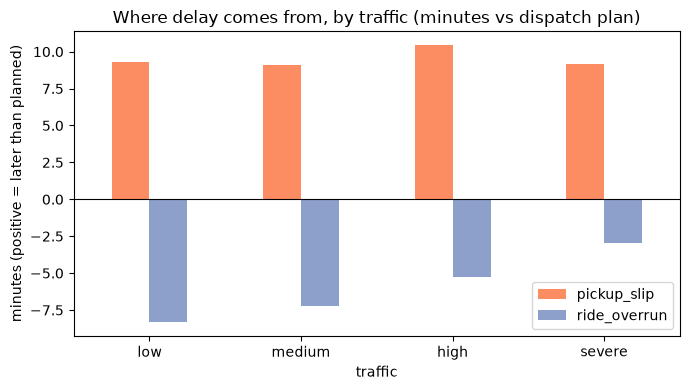

In [20]:
# the big one: what does dispatch assume about pickup?
x["assumed_prep_min"] = (x["estimated_pickup_at"] - x["created_at"]).dt.total_seconds() / 60
print("estimated_pickup_at minus created_at, every order:")
print(x["assumed_prep_min"].describe().round(2))

v = x[x["order_id"].isin(d["order_id"])].copy()
v = v.merge(d[["order_id", "delay_min", "late", "prep_min", "ride_min"]], on="order_id", suffixes=("_x", ""))
v = v.dropna(subset=["prep_min"])
v["pickup_slip"] = v["prep_min"] - v["assumed_prep_min"]                                                     # later than dispatch planned
v["ride_overrun"] = v["ride_min"] - (v["promised_eta"] - v["estimated_pickup_at"]).dt.total_seconds() / 60  # road leg vs plan
print("\ncheck: delay == pickup_slip + ride_overrun:", np.allclose(v["delay_min"], v["pickup_slip"] + v["ride_overrun"]))

print("\naverage minutes, late vs on time:")
display(v.groupby("late")[["pickup_slip", "ride_overrun", "delay_min"]].mean().round(1))
lv = v[v["late"]]
share = lv["pickup_slip"].clip(lower=0).sum() / (lv["pickup_slip"].clip(lower=0).sum() + lv["ride_overrun"].clip(lower=0).sum())
print(f"share of late minutes that come from pickup slipping: {share:.0%}")

v["traffic"] = pd.Categorical(v["traffic"], traffic_order, ordered=True)
by_t = v.groupby("traffic", observed=True)[["pickup_slip", "ride_overrun"]].mean()
by_t.plot(kind="bar", figsize=(7, 4), color=["#fc8d62", "#8da0cb"])
plt.axhline(0, color="black", lw=0.8)
plt.title("Where delay comes from, by traffic (minutes vs dispatch plan)")
plt.ylabel("minutes (positive = later than planned)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Challenge 4 answer

Ingestion is complete and I can prove it: 32 pages, 1,600 records, matches `total_records`, no duplicate ids, and the id set is exactly the same as the order table. Page 3 came back 500 and page 5 came back 429 on the first try, both retried (429 waits the `retry_after_seconds` the API asked for) and succeeded. Every successful raw page is saved untouched, plus a manifest with the checks and every request attempt. Non-retryable errors raise instead of quietly returning a partial list.

What dispatch adds that the order table doesn't:
- 95 orders were reassigned. `orders.driver_id` holds the original driver for all of them, so any driver-level analysis on the order table blames the wrong driver.
- 3 orders with no `driver_id` in the DB have one in dispatch.
- The big one: `estimated_pickup_at` is exactly 18 minutes after the order for every single order. Real pickup takes ~26 min on median. So the promise is built on a pickup time that's usually wrong.
- Split the delay into "pickup was later than planned" + "ride was longer than planned" and it adds up exactly. The ride leg actually beats the plan on average (~6.6 min early) in every traffic bucket. Pickup slips ~9.5 min on average. About 99% of late minutes come from pickup slipping.

That's the real answer to "traffic is the problem": traffic shrinks the buffer on the ride leg (it's smaller in severe traffic), but the thing blowing through the buffer is the fixed 18 min pickup assumption.

# Challenge 5: Can we attribute the delay?

Inspect `driver_events.json`.

Look for:
- assignment,
- GPS pings,
- pickup,
- delivery.

Then answer:

> **Can we reliably tell when the driver arrived at the restaurant?**

Be precise about:
- **Observed** = directly stored.
- **Inferred** = estimated from another signal, such as GPS.

### Required output

| Event / fact | Observed? | Source | Reliability concern |
|---|---|---|---|
| Driver assigned |  |  |  |
| Driver at restaurant |  |  |  |
| Picked up |  |  |  |
| Delivered |  |  |  |

In [21]:
flat_sorted = flat.sort_values(["driver_id", "timestamp"])
out_of_order = sum((g["timestamp"].diff() < pd.Timedelta(0)).sum() for _, g in flat.groupby("driver_id"))
print("events stored out of time order (need sorting before use):", out_of_order)

print("\nevent types:")
display(flat["type"].value_counts())
print("explicit arrived-at-restaurant event?",
      any("arriv" in t_ for t_ in flat["type"].unique()))

per_order = flat.groupby(["order_id", "type"]).size().unstack(fill_value=0)
print("\nper order event counts:")
display(per_order.describe().round(2))

events stored out of time order (need sorting before use): 2314

event types:


type
gps_ping     5371
assigned     1600
picked_up    1532
delivered    1532
Name: count, dtype: int64

explicit arrived-at-restaurant event? False

per order event counts:


type,assigned,delivered,gps_ping,picked_up
count,1600.0,1600.00,1600.00,1600.00
mean,1.0,0.96,3.36,0.96
std,0.0,0.20,1.31,0.20
min,1.0,0.00,0.00,0.00
25%,1.0,1.00,2.00,1.00
50%,1.0,1.00,3.00,1.00
75%,1.0,1.00,5.00,1.00
max,1.0,1.00,5.00,1.00


In [22]:
# can GPS stand in for "arrived at restaurant"?
restaurants_db = pd.read_sql("SELECT restaurant_id, lat AS r_lat, lon AS r_lon FROM restaurants", con)
pings = (flat[flat["type"] == "gps_ping"]
         .merge(orders[["order_id", "restaurant_id", "pickup_fixed"]], on="order_id")
         .merge(restaurants_db, on="restaurant_id"))

in_city = pings["lat"].between(12.5, 13.5) & pings["lon"].between(77, 78.2)
print("pings with impossible coordinates (not in Bengaluru):", (~in_city).sum(), "of", len(pings))
pings = pings[in_city].copy()

pings["km_from_restaurant"] = np.hypot((pings["lat"] - pings["r_lat"]) * 111, (pings["lon"] - pings["r_lon"]) * 108)
gap = pings.sort_values("timestamp").groupby("order_id")["timestamp"].apply(lambda s: s.diff().dt.total_seconds().median() / 60)
print(f"median gap between pings: {gap.median():.0f} min")

before = pings[pings["timestamp"] < pings["pickup_fixed"]]
print(f"pings before pickup: median {before['km_from_restaurant'].median():.1f} km from the restaurant")
print("pings within 300 m of the restaurant, whole dataset:", (pings["km_from_restaurant"] < 0.3).sum())

# assignment: one event per order even when dispatch reassigned it
asg = flat[flat["type"] == "assigned"].merge(dispatch[["order_id", "driver_id", "original_driver_id", "assigned_at", "reassigned_at"]], on="order_id", suffixes=("_app", ""))
re = asg[asg["reassigned_at"].notna()]
print(f"\nreassigned orders: {len(re)} | app 'assigned' time == first assignment: {(re['timestamp'] == re['assigned_at']).mean():.0%}"
      f" | app driver == new driver: {(re['driver_id_app'] == re['driver_id']).mean():.0%}")

pings with impossible coordinates (not in Bengaluru): 171 of 5361


median gap between pings: 15 min
pings before pickup: median 3.8 km from the restaurant
pings within 300 m of the restaurant, whole dataset: 6

reassigned orders: 95 | app 'assigned' time == first assignment: 100% | app driver == new driver: 100%


### Challenge 5 answer

No, we can't reliably tell when the driver got to the restaurant. There's no arrival event, and GPS can't fill the gap:
- pings come every ~15 min, so a driver could arrive, wait and leave between two pings
- ~170 pings have coordinates that aren't anywhere near Bengaluru (latitudes up to ~81), so the feed has corruption
- pings before pickup are ~4 km from the restaurant on median, and only a handful in the whole dataset are within 300 m

Also the events inside each driver's array aren't in time order, you have to sort them before doing anything.

| Event / fact | Observed? | Source | Reliability concern |
|---|---|---|---|
| Driver assigned | Observed | driver_events `assigned`, dispatch `assigned_at` | For the 95 reassigned orders the app shows one `assigned` event with the new driver's id but the original assignment time. Reassignment time only lives in dispatch |
| Driver at restaurant | Not observed. Inferred at best | GPS pings | No event. Pings too sparse (~15 min) and some corrupted, so even inference is shaky |
| Picked up | Observed | driver_events `picked_up`, orders `pickup_at` | DB is wrong for 5 orders and has fake pickups on cancelled orders. Driver app looks cleaner |
| Delivered | Observed | orders `actual_delivery_at`, driver_events `delivered` | DB missing 37, driver app has them and matches 100% where both exist |

This matters because Challenge 2 and 4 say the delay lives in the pickup window. Without arrival and food-ready events we can't split that into "kitchen was slow" vs "driver showed up late", which is exactly the split you need to decide who fixes it.

In [23]:
# last check before the slide: does a smarter non-AI pickup estimate fix it?
# train on Aug 1-14, test on Aug 15-28. per restaurant median pickup time instead of a flat 18 min
v["created_at"] = pd.to_datetime(v["created_at"])
train, test = v[v["created_at"] < "2026-08-15"], v[v["created_at"] >= "2026-08-15"].copy()
rest_prep = train.groupby("restaurant_id")["prep_min"].median()
ride_bias = train["ride_overrun"].median()

new_prep = test["restaurant_id"].map(rest_prep).fillna(train["prep_min"].median())
test["new_delay"] = test["delay_min"] - (new_prep - 18) - ride_bias

cmp_ = pd.DataFrame({
    "current ETA": [(test["delay_min"] > 0).mean(), test["delay_min"].abs().mean()],
    "per-restaurant pickup ETA": [(test["new_delay"] > 0).mean(), test["new_delay"].abs().mean()],
}, index=["late rate", "mean abs error (min)"]).round(3)
display(cmp_)
print("within-restaurant spread of pickup time (median std, min):", round(v.groupby("restaurant_id")["prep_min"].std().median(), 1))

,current ETA,per-restaurant pickup ETA
late rate,0.555,0.496
mean abs error (min),8.407,8.898


within-restaurant spread of pickup time (median std, min): 9.8


# Final FDE synthesis: one slide only

Your final slide must answer:

1. **Problem size**: how large is the late-delivery problem?
2. **Evidence**: what appears related to delay?
3. **Trusted sources**: which sources do you trust for which facts?
4. **Uncertainty**: what can you not determine confidently?
5. **Instrumentation recommendation**: what should FlashEats capture/fix next?
6. **Decision**: would you build the AI delay predictor now? Why or why not?

Use language such as:
- “The data shows…”
- “This is associated with…”
- “We cannot determine…”
- “We would need X before concluding Y…”

### My slide

1. Problem size. The data shows ~56% of delivered orders arrive after the promised time, but only ~22% are more than 10 min late. Median lateness among late orders is ~7 min. The metric only holds up after deduping 3 orders, backfilling 37 missing delivery times from the driver app, and dropping 4 broken ETAs.

2. Evidence. Nearly all of the late time (~99%) comes from the pickup happening later than planned. Dispatch assumes pickup at exactly order + 18 min for every order, real pickups take ~26 min. The ride leg usually beats its plan. Traffic and rain are associated with more lateness because they shrink the ride buffer, but they're not the root.

3. Trusted sources. Order platform for the promise and the outcome (with driver app backfill). Dispatch for who drove and what the ETA assumed. Driver app for pickup/delivery times. Tickets and restaurant status are context only.

4. Uncertainty. We cannot determine whether the pickup delay is slow kitchens or drivers arriving late, there's no arrival or food-ready event. Distance is a placeholder (18.0 km) for half the orders. Ticket timestamps don't line up with what the tickets say. Cancelled orders have no cancel time or reason.

5. Instrument next. `driver_arrived_at_restaurant` (geofence), `food_ready_at` from the restaurant, reassignment history as events, cancellation time + reason, real distance, and GPS pings every ~1 min with basic validation.

6. Decision. Don't build the AI delay predictor yet. The biggest error is a hard-coded 18 min pickup, and the signal that would fix it (when food is actually ready, when the driver actually arrived) isn't captured, so a model would be learning from the same blind spot. I even tried the obvious cheap fix, a per-restaurant pickup estimate instead of the flat 18 min (trained on Aug 1 to 14, tested on Aug 15 to 28). Late rate drops a bit only because the promises get longer, and the average ETA error actually gets worse (8.4 to 8.9 min). Pickup time swings ~10 min order to order inside the same restaurant, so a per-restaurant number can't catch it. We'd need the food-ready and arrival events before a predictor has anything real to learn from. Capture those for a few weeks, then revisit.

In [24]:
# Optional cleanup
try:
    con.close()
except Exception:
    pass

try:
    api_proc.terminate()
except Exception:
    pass

print("Session cleanup complete.")

Session cleanup complete.
